# jacscanomaly quickstart

One light curve is one `Event`; each step is a method and the results stay on it.
The data are a simulated Roman event (`example_data.npy`: time, flux, flux error).

In [1]:
import numpy as np
from jacscanomaly import Event

time, flux, ferr = np.load("example_data.npy").T
ev = Event(time, flux, ferr)

## 1. Fit a single lens and scan the residual

The scan looks for short bumps and dips; a detection has `score >= 10`.

In [2]:
ev.fit("pspl")

Fit(model='pspl', params={'t0': 9826.560714021854, 'tE': 8.616003538088025, 'u0': 0.3532817994846128}, fs=9.661792787384348e-10, fb=1.5384043218522003e-09, chi2=40468.93111514455, J=np.float64(40521.98133724458))

In [3]:
pspl_scan = ev.scan()
pspl_scan.detected, [(round(c.t0, 3), round(c.teff, 3), round(c.score, 1)) for c in pspl_scan.detections]

(True, [(9826.001, 0.3, 55.0)])

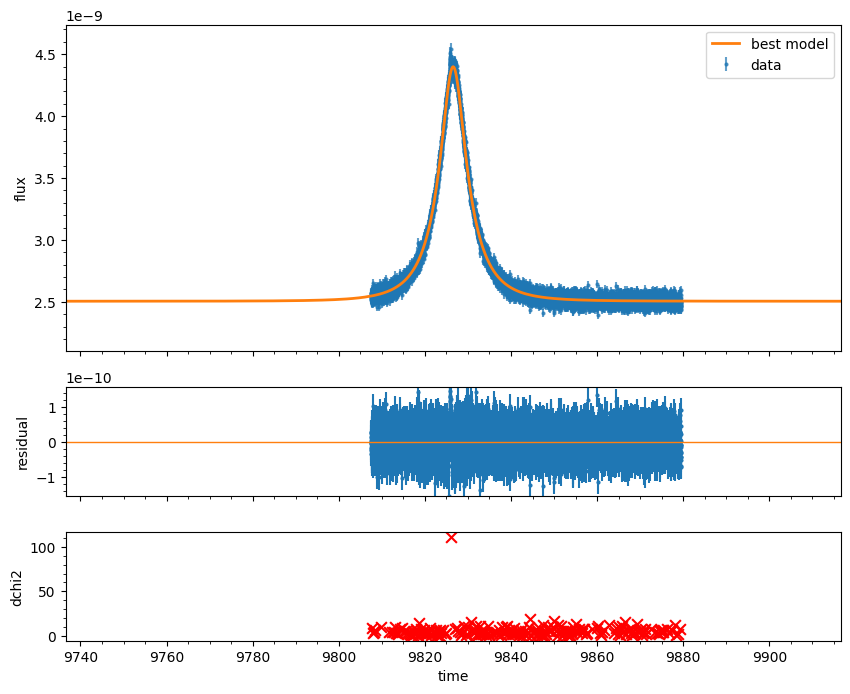

In [4]:
ev.plot_result("pspl");

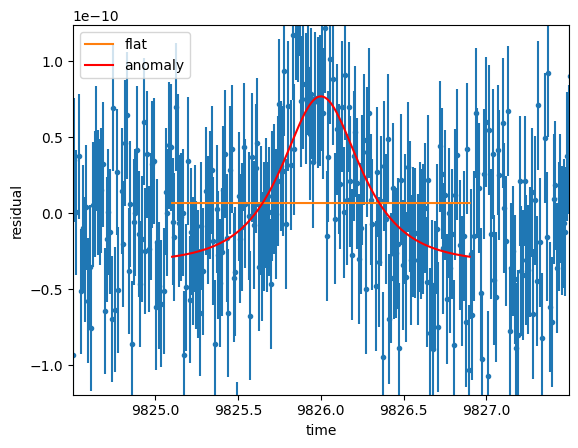

In [5]:
ev.plot_anomaly_window("pspl");

## 2. Try a finite source

A finite source can make a short deviation too. Refit and scan again.

In [6]:
ev.fit("fspl", start="pspl")
fspl_scan = ev.scan()
fspl_scan.detected

True

Parallax is tried the same way, `ev.fit("parallax", start="pspl")`, once the event
has a sky position (and a spacecraft ephemeris for a satellite):

```python
ev = Event(time, flux, ferr, ra_deg=..., dec_deg=..., ephemeris="roman.txt")
```

This simulated event has none, so it is skipped here.

## 3. Fit the anomaly

The finite source does not explain it, so the host is fitted together with the
anomaly ("atoms"). Each feature is one anomaly window: shape, peak time, FWHM,
the `dchi2` it explains.

In [7]:
for model in ev.fits:
    ev.fit_atoms(model)

f = ev.atoms["pspl"].features[0]
f.kind, round(f.time, 3), round(f.timescale, 3), round(f.dchi2, 1), f.caustic

('bump', 9826.005, 0.391, 150.3, False)

In [8]:
ev.summary()

,model,chi2,J,detected,n_detections,best_score,atoms_J,n_atoms,host_identified
0,pspl,40468.931115,40521.981337,True,1,55.020531,40435.862351,1,True
1,fspl,40468.931097,40532.591363,True,1,55.020209,40446.477882,1,True


## 4. Save

In [9]:
ev.write_json("event.json");